# 阶段 0 作业

题目、你的代码、你的答案都写在这个笔记本里：代码写进代码格，文字答案双击「你的答案」那格编辑。做完保存，告诉我「批改」。

满分 100：简单 10 + 中等 30 + 中等 30 + 困难 30。

---
## 简单题 · 形状预判（10 分）

先**不要运行**，在脑子里推出每一行结果的 shape，写进下面「你的答案」；然后在代码格里验证。猜错的，写一句为什么。

```python
x = torch.randn(2, 3, 4)

x.sum(dim=1)            # ①
x.transpose(0, 2)       # ②
x.reshape(6, -1)        # ③
x @ torch.randn(4, 5)   # ④
x[:, 0]                 # ⑤
```

**你的答案**（先别运行代码）：

- ① 我理解这个函数是，按照第一个维度求和，那么它的维度就是[2,4]
- ② 把第0和第二个维度转秩，就是交换，那么它的维度就是[4,3,2]
- ③ 重塑造为第0个维度是6，那应该是4，也就是[6,4]
- ④ [2,3,5]
- ⑤ x[:, 0]，前面:表示最开始的0维度全部需要，也就是2表示第0维度全要，后面的0表示第一个维度只取0个，所以最后的结果是[2,4]

In [10]:
# 写完答案再来这里验证
import torch

x = torch.randn(2, 3, 4)

print(x.sum(dim=1).shape)
print(x.transpose(0, 2).shape)       
print(x.reshape(6, -1).shape)     
print((x @ torch.randn(4, 5)).shape)
print(x[:, 0].shape)                            

torch.Size([2, 4])
torch.Size([4, 3, 2])
torch.Size([6, 4])
torch.Size([2, 3, 5])
torch.Size([2, 4])


**猜错的，为什么：**

修正x[:, 0]，表示第0维度全要，后面的0表示第一个维度只取0个，也就是消失了一个维度然后就是[2,4]

---
## 中等题 1 · 找交叉点（30 分）

课上只比了 4096×4096 这一个尺寸。矩阵小的时候呢？

1. n 取 32、64、128、256、512、1024、2048、4096，分别测 CPU 和 MPS 的耗时。可以直接复制课上的 `sync` 和 `bench`。小矩阵算得太快，重复次数要多一些，比如 100 次。
2. 用 matplotlib 画一张图：横轴 n，纵轴耗时，CPU 和 MPS 各一条线，两个轴都用对数刻度（`plt.loglog`）。
3. 从多大的 n 开始 MPS 比 CPU 快？为什么矩阵小的时候 GPU 反而不占优？
4. 附加：把 `sync()` 里的 `torch.mps.synchronize()` 注释掉，再测一次 MPS。时间变成了多少？这说明了什么？

32×32 矩阵乘法，平均一次：
  CPU :      0.0 ms   0.00 TFLOPS
  MPS :      0.4 ms   0.00 TFLOPS
  mps 是 CPU 的 0.1 倍速度
64×64 矩阵乘法，平均一次：
  CPU :      0.0 ms   0.19 TFLOPS
  MPS :      0.1 ms   0.00 TFLOPS
  mps 是 CPU 的 0.0 倍速度
128×128 矩阵乘法，平均一次：
  CPU :      0.0 ms   0.41 TFLOPS
  MPS :      0.2 ms   0.02 TFLOPS
  mps 是 CPU 的 0.0 倍速度
256×256 矩阵乘法，平均一次：
  CPU :      0.0 ms   0.82 TFLOPS
  MPS :      0.1 ms   0.33 TFLOPS
  mps 是 CPU 的 0.4 倍速度
512×512 矩阵乘法，平均一次：
  CPU :      0.2 ms   1.48 TFLOPS
  MPS :      0.3 ms   0.81 TFLOPS
  mps 是 CPU 的 0.5 倍速度
1024×1024 矩阵乘法，平均一次：
  CPU :      1.4 ms   1.50 TFLOPS
  MPS :      1.5 ms   1.48 TFLOPS
  mps 是 CPU 的 1.0 倍速度
2048×2048 矩阵乘法，平均一次：
  CPU :     12.2 ms   1.41 TFLOPS
  MPS :      4.7 ms   3.68 TFLOPS
  mps 是 CPU 的 2.6 倍速度
4096×4096 矩阵乘法，平均一次：
  CPU :     99.5 ms   1.38 TFLOPS
  MPS :     36.0 ms   3.81 TFLOPS
  mps 是 CPU 的 2.8 倍速度
8192×8192 矩阵乘法，平均一次：
  CPU :    771.5 ms   1.43 TFLOPS
  MPS :    295.4 ms   3.72 TFLOPS
  mps 是 CPU 的 2.6 倍速度


/Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30697 (\N{CJK UNIFIED IDEOGRAPH-77E9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 38453 (\N{CJK UNIFIED IDEOGRAPH-9635}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36793 (\N{CJK UNIFIED IDEOGRAPH-8FB9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 38271 (\N{CJK UNIFIED IDEOGRAPH-957F}) missing from font(s) DejaVu 

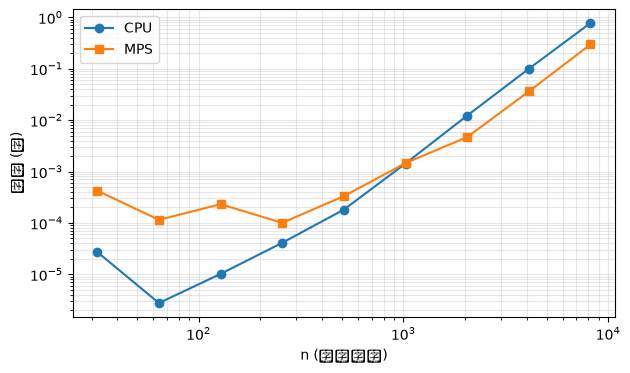

In [16]:
import time

import matplotlib.pyplot as plt
import torch

# 你的代码
device = "mps" if torch.backends.mps.is_available() else "cpu"
def sync(dev):
    # GPU 是异步的：Python 把命令发出去就往下走，不等它算完。
    # 所以计时前后都要等 GPU 把手上的活干完，否则测出来的时间是假的。
    if dev.type == "mps":
        torch.mps.synchronize()


def bench(a, b, repeat=10):
    """返回 a @ b 平均一次的耗时（秒）。"""
    a @ b  # 预热：第一次调用要做初始化，不计时
    sync(a.device)
    start = time.perf_counter()
    for _ in range(repeat):
        # TODO 3：用 @ 做一次矩阵乘法，a 乘 b，结果存成 c
        c = a @ b
    sync(a.device)
    assert c is not None, "先完成 TODO 3"
    return (time.perf_counter() - start) / repeat
cpu_times = []   
mps_times = []
ns = [32,64,128,256,512,1024,2048,4096,8192]
for n in ns:
    a = torch.randn(n, n)
    b = torch.randn(n, n)

    t_cpu = bench(a, b)
    t_dev = bench(a.to(device), b.to(device))

    flops = 2 * n**3  # n×n 的矩阵乘一次，大约要做 2n³ 次浮点运算
    print(f"{n}×{n} 矩阵乘法，平均一次：")
    print(f"  CPU : {t_cpu * 1000:8.1f} ms   {flops / t_cpu / 1e12:.2f} TFLOPS")
    print(f"  {device.upper():4}: {t_dev * 1000:8.1f} ms   {flops / t_dev / 1e12:.2f} TFLOPS")
    print(f"  {device} 是 CPU 的 {t_cpu / t_dev:.1f} 倍速度")
    cpu_times.append(t_cpu)
    mps_times.append(t_dev)

plt.figure(figsize=(7, 4))
plt.loglog(ns, cpu_times, "o-", label="CPU")   # "o-" = 圆点 + 连线
plt.loglog(ns, mps_times, "s-", label="MPS")   # "s-" = 方块 + 连线
plt.xlabel("n (矩阵边长)")
plt.ylabel("耗时 (秒)")
plt.legend()                                    # 显示图例，就是哪条线是谁
plt.grid(True, which="both", alpha=0.3)        # 加网格，读数方便
plt.show()

**你的答案：**

- 交叉点：大约就是1024矩阵的原因
- 小矩阵 GPU 不占优的原因：gpu的计算，不是简单的理解为矩阵乘法就是了，还有固定的开销时间，可以理解为调用gpt的时间，也就是命令打包发给gpu，gpu的调度，同步等待等。也就是这个固定开销时间摆在这里，如果计算的时间太少的话，就会显得cpu更快。
- 去掉 synchronize 之后：去掉之后在参数n等于256的时候cpu时间和mps时间是一样的，这个是单独跑试验做出来的结果。

---
## 中等题 2 · 算一笔内存账（30 分）

一个模型有多大，说到底就是「参数个数 × 每个参数占几个字节」。

1. 用 `torch.tensor([], dtype=...).element_size()` 打印 `float32`、`float16`、`bfloat16`、`int8` 每个数各占几个字节。
2. 填下面「你的答案」里的表，单位 GB（1 GB 按 10⁹ 字节算；int4 每个参数算 0.5 字节）。
3. 你的 Mac 有 16 GB 内存。只看参数的话，哪几格装得下？为什么「刚好装得下」的那几格实际上也跑不起来？（先凭直觉猜：跑模型时除了参数还要存什么？阶段 8 会讲清楚。）

In [27]:
import torch

# 你的代码
for type in [torch.float32, torch.float16,torch.bfloat16, torch.int8]:
    t = torch.tensor([], dtype=type)   # 建一个空张量，指定每个数用 float16 存
    print(t.element_size())                     # 每个元素占几个字节

4
2
2
1


**你的答案：**

| 参数量 | float32 | float16 | int8 | int4 |
|---|---|---|---|---|
| 0.5B（5 亿） | 2GB |1GB  |0.5GB  |0.25GB  |
| 7B | 28GB |14GB  | 7GB |3.5GB  |
| 70B | 280GB |140GB  |70GB  |35GB  |

- 16 GB 装得下的格子：能装下最大7B的float16模型,然后还可以装下0.5b的所有参数的模型，7B的int8和int4都可以。
- 刚好装得下也跑不起来，因为：因为模型推理，肯定还需要其他的步骤也会占用内存，以及计算机的其他部分也是需要有这个占用内存的应用存在。

---
## 困难思考题 · 统一内存（30 分，不用写代码）

在装 NVIDIA 显卡的电脑上，CPU 用内存，显卡用自己的显存，`.to("cuda")` 要把数据从一块内存真的搬到另一块。而 M1 的 CPU 和 GPU 共用同一块内存，叫「统一内存」。

1. 那么在 Mac 上，`.to("mps")` 还要做什么事吗？会不会完全不花时间？说说你的推测。想验证的话，可以在下面的代码格写个小实验。
2. 很多人用 Mac 在本地**跑**大模型，可是**训练**大模型几乎都租 NVIDIA 显卡。结合你在中等题 1、2 里测到和算出的数字，说说为什么。

**你的答案：**

1.我觉得肯定会做很多事情的，比如.to()这个函数就需要花时间，也就是把矩阵放到GPT中的时间。
2.因为训练的过程中，计算量巨大，就像你提到的h100的TFLOPS是我这台电脑的100倍以上，所以很明显我们是无法在mac上训练大模型的，而推理过程中用到的计算量大概率就要小很多
3、并且苹果的MPS 只支持一块 GPU，也就是所谓的统一内存。没法多卡并行训练。

In [ ]:
# （可选）验证实验